# Spread Locator: A Statistical Distribution Analysis Model
**Subject:** Mathematics & Advanced Statistics  |  **Project:** PR #3

**Business problem.** An e-commerce platform wants to know whether daily customer transactions follow known statistical distributions, how to handle skewed transaction amounts, and what probability insights can be drawn.

**Notebook roadmap**
1. Data loading & overview
2. Bernoulli & Binomial fits (transaction occurrence & weekly count)
3. Poisson fit (transactions per day)
4. Log-Normal & Power Law models for transaction amounts
5. Q-Q plot (normality test)
6. Box-Cox transform (variance stabilisation)
7. Z-scores & P(amount > ₹5000)
8. PDF & CDF plots
9. Final conclusion & business insights

In [1]:
import os, warnings
import numpy as np, pandas as pd
import scipy.stats as st
from scipy.optimize import minimize
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 10})
os.makedirs("images", exist_ok=True)
SAVE = lambda name: plt.savefig(f"images/{name}.png", bbox_inches="tight")
PALETTE = {"obs": "#4C72B0", "fit": "#DD8452", "alt": "#55A868", "bad": "#C44E52"}

## 1. Data loading & overview

In [2]:
df = pd.read_csv("spread_locator_dataset.csv", parse_dates=["transaction_date"])
x = df["transaction_amount"].values
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()), "| Duplicate rows:", int(df.duplicated().sum()),
      "| Duplicate transaction_id:", int(df.transaction_id.duplicated().sum()))
print("Date range:", df.transaction_date.min().date(), "to", df.transaction_date.max().date())
display(df.head())
display(df.describe().round(2))
print("\nSkewness :", round(st.skew(x), 3), "| Excess kurtosis:", round(st.kurtosis(x), 3))
print("Status counts:\n", df.transaction_status.value_counts().to_string())
print("Region counts:\n", df.region.value_counts().to_string())

Shape: (220, 7)
Missing values: 0 | Duplicate rows: 0 | Duplicate transaction_id: 0
Date range: 2023-01-01 to 2023-01-31


,transaction_id,customer_id,transaction_amount,transaction_date,transaction_count,region,transaction_status
0,e98aa092-3770-4fdb-9502-5b5a6a244811,CUST2824,3821.34,2023-01-26,3,North,Fail
1,11ba6918-dba0-41e5-96cf-f5a7b95f0103,CUST1409,2781.84,2023-01-28,0,East,Fail
2,82b7654b-6eb7-4579-89a0-1a9edec0a7bb,CUST5506,4120.97,2023-01-28,0,South,Fail
3,f7166574-f400-4d53-b526-0b11f6619ddf,CUST5012,6383.78,2023-01-18,2,South,Success
4,8632fe26-b507-4068-9c68-1b2fa04fecb3,CUST4657,2651.61,2023-01-04,4,North,Success


,transaction_amount,transaction_date,transaction_count
count,220.00,220,220.00
mean,3365.19,2023-01-15 17:14:10.909091,2.85
min,804.42,2023-01-01 00:00:00,0.00
25%,2124.20,2023-01-07 00:00:00,1.75
50%,3077.72,2023-01-16 00:00:00,3.00
75%,3950.74,2023-01-23 06:00:00,4.00
max,20462.84,2023-01-31 00:00:00,9.00
std,1985.71,NaN,1.80



Skewness : 3.73 | Excess kurtosis: 25.333
Status counts:
 transaction_status
Fail       122
Success     98
Region counts:
 region
West     66
South    59
East     50
North    45


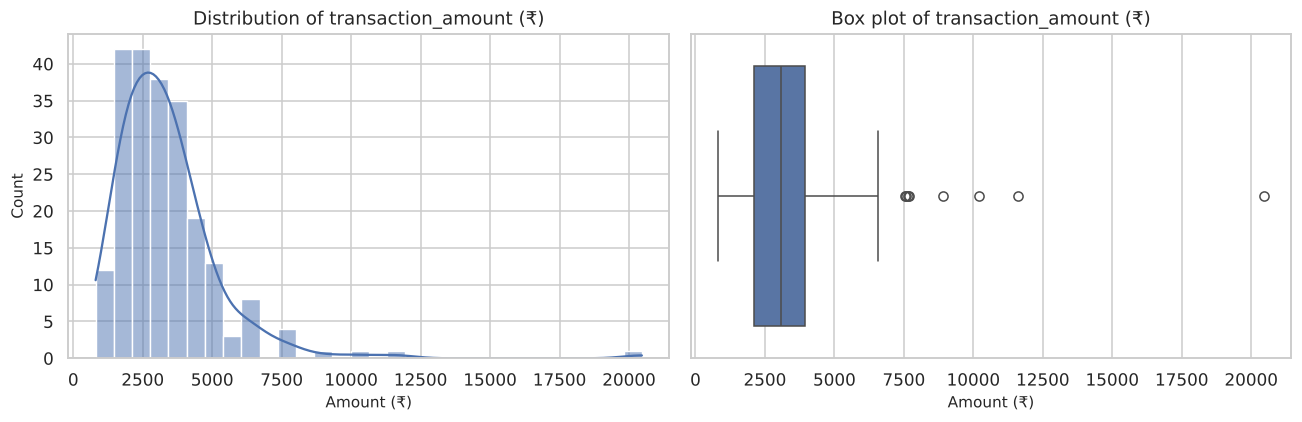

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(x, bins=30, kde=True, color=PALETTE["obs"], ax=ax[0])
ax[0].set(title="Distribution of transaction_amount (₹)", xlabel="Amount (₹)")
sns.boxplot(x=x, color=PALETTE["obs"], ax=ax[1])
ax[1].set(title="Box plot of transaction_amount (₹)", xlabel="Amount (₹)")
plt.tight_layout(); SAVE("01_amount_overview"); plt.show()

**Interpretation.** The amounts are strongly **right-skewed** (skewness ≈ 3.73, much larger than 0 for a symmetric distribution), with the mean (₹3,365) well above the median (₹3,078) and a long tail reaching ₹20,463. The box plot flags several high-value outliers. This already hints that a normal model will fit poorly and that a positively-skewed model (e.g. Log-Normal) is a better candidate.

## 2. Bernoulli & Binomial distributions

**Bernoulli (transaction occurrence).** Each transaction is a single trial with two outcomes, so `transaction_status` is coded as 1 = Success, 0 = Fail. We also look at weekly *occurrence* (did the customer transact at all in the week? `transaction_count > 0`).

Bernoulli MLE  p(Success)            = 0.4455   (variance p(1-p) = 0.2470)
Bernoulli MLE  p(active in the week) = 0.9318   (variance p(1-p) = 0.0635)
Exact test H0: p=0.5 -> p-value = 0.1208


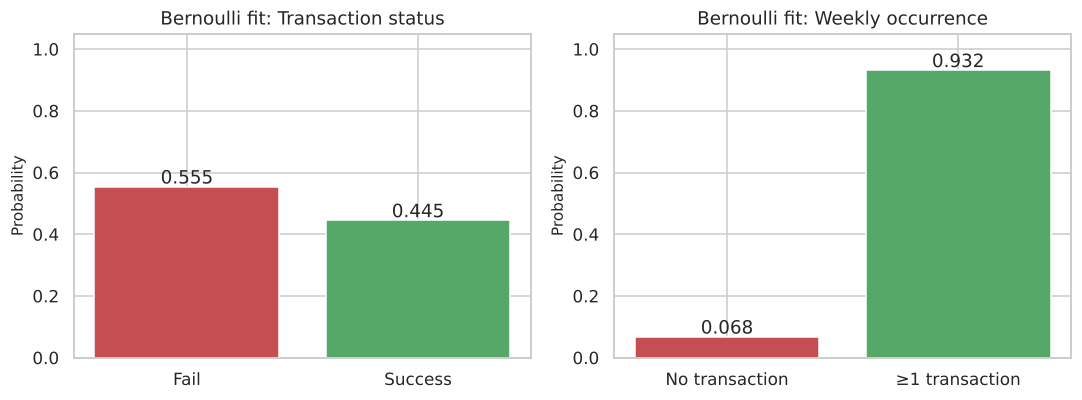

In [4]:
success = (df.transaction_status == "Success").astype(int)
p_succ = success.mean()
occ = (df.transaction_count > 0).astype(int)
p_occ = occ.mean()
print(f"Bernoulli MLE  p(Success)            = {p_succ:.4f}   (variance p(1-p) = {p_succ*(1-p_succ):.4f})")
print(f"Bernoulli MLE  p(active in the week) = {p_occ:.4f}   (variance p(1-p) = {p_occ*(1-p_occ):.4f})")
# exact binomial test: is success rate different from 50 %?
bt = st.binomtest(int(success.sum()), len(success), 0.5)
print(f"Exact test H0: p=0.5 -> p-value = {bt.pvalue:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, p, lab, names in [(ax[0], p_succ, "Transaction status", ["Fail", "Success"]),
                         (ax[1], p_occ, "Weekly occurrence", ["No transaction", "≥1 transaction"])]:
    obs = [1 - p, p]
    a.bar(names, obs, color=[PALETTE["bad"], PALETTE["alt"]])
    for i, v in enumerate(obs): a.text(i, v + 0.01, f"{v:.3f}", ha="center")
    a.set(title=f"Bernoulli fit: {lab}", ylabel="Probability", ylim=(0, 1.05))
plt.tight_layout(); SAVE("02_bernoulli"); plt.show()

**Interpretation.** The Bernoulli parameter for transaction success is **p ≈ 0.445**: only about 44.5 % of transactions succeed while 55.5 % fail. The exact binomial test (p-value ≈ 0.12) says this is not statistically different from a fair coin (50 %) at the 5 % level, but a failure rate above 50 % is still a business red flag. Weekly occurrence is much higher (p ≈ 0.93): about 93 % of customer-weeks contain at least one transaction attempt.

Binomial(n=9, p=0.3172) | mean=2.855, var=1.949
Observed        | mean=2.855, var=3.230
Chi-square GOF: chi2=38.380, dof=5, p-value=0.0000


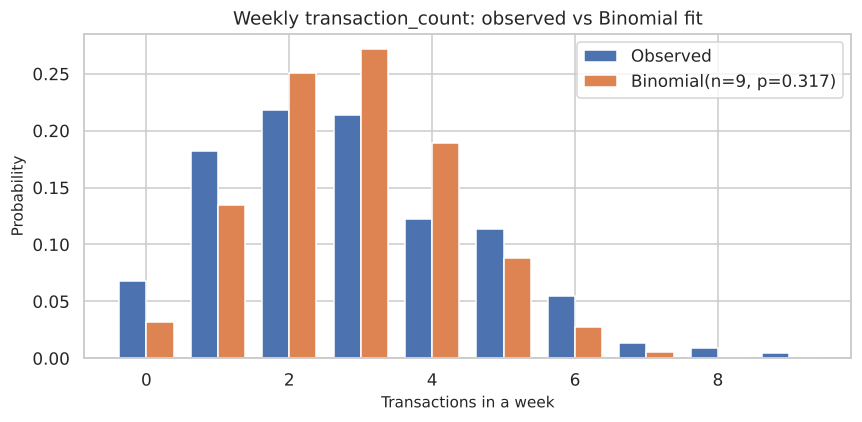

In [5]:
cnt = df.transaction_count
n_trials = int(cnt.max())                     # max possible transactions in a week (observed ceiling)
p_bin = cnt.mean() / n_trials                 # MLE of p when n is fixed
k = np.arange(0, n_trials + 1)
obs_freq = cnt.value_counts().reindex(k, fill_value=0).values
exp_freq = st.binom.pmf(k, n_trials, p_bin) * len(cnt)
print(f"Binomial(n={n_trials}, p={p_bin:.4f}) | mean={n_trials*p_bin:.3f}, var={n_trials*p_bin*(1-p_bin):.3f}")
print(f"Observed        | mean={cnt.mean():.3f}, var={cnt.var():.3f}")

# Chi-square goodness of fit: pool tail so expected counts >= 5
def pool(obs, exp, minexp=5):
    o, e, ob, eb = [], [], 0, 0
    for oi, ei in zip(obs, exp):
        ob += oi; eb += ei
        if eb >= minexp: o.append(ob); e.append(eb); ob = eb = 0
    if eb > 0: o[-1] += ob; e[-1] += eb
    return np.array(o), np.array(e)
o, e = pool(obs_freq, exp_freq); e = e * o.sum() / e.sum()
chi2 = ((o - e) ** 2 / e).sum(); dof = len(o) - 1 - 1
print(f"Chi-square GOF: chi2={chi2:.3f}, dof={dof}, p-value={1-st.chi2.cdf(chi2, dof):.4f}")

fig, ax = plt.subplots(figsize=(8, 4))
w = 0.38
ax.bar(k - w/2, obs_freq / len(cnt), w, label="Observed", color=PALETTE["obs"])
ax.bar(k + w/2, st.binom.pmf(k, n_trials, p_bin), w, label=f"Binomial(n={n_trials}, p={p_bin:.3f})", color=PALETTE["fit"])
ax.set(title="Weekly transaction_count: observed vs Binomial fit", xlabel="Transactions in a week", ylabel="Probability")
ax.legend(); plt.tight_layout(); SAVE("03_binomial"); plt.show()

**Interpretation.** Treating each weekly count as a Binomial with *n* = 9 (the highest count observed) gives **p ≈ 0.317**. The fitted mean (2.85) matches the data exactly by construction, and the fitted variance (≈ 1.95) is **lower** than the observed variance (≈ 3.23), so the real data are *over-dispersed* relative to a Binomial: the observed counts are more spread out than a fixed-*n* model allows. The chi-square goodness-of-fit test confirms this (χ² ≈ 38.4, 5 d.o.f., p < 0.001), so the **Binomial model is rejected** for weekly counts: it is only a rough first approximation, and a more flexible count model (e.g. Negative Binomial) would suit better.

## 3. Poisson distribution (number of transactions per day)

Days = 31, mean (lambda-hat) = 7.097, variance = 5.290, dispersion index (var/mean) = 0.745
Dispersion test: stat=22.36, two-sided p-value=0.3190


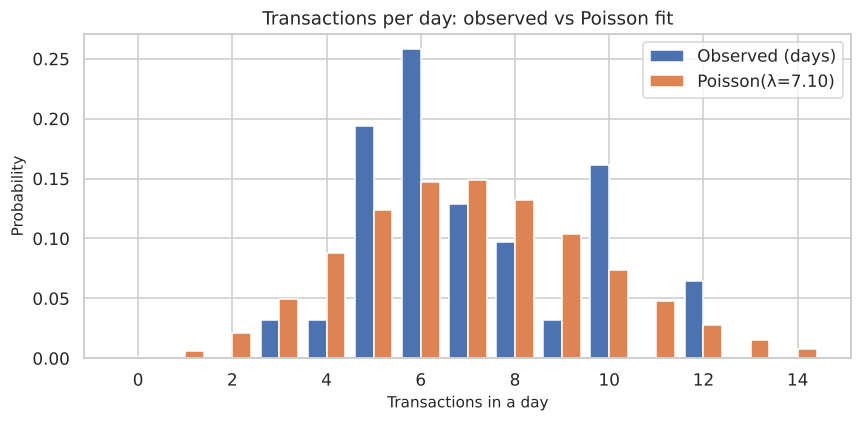

P(a day has >= 10 transactions) under Poisson: 0.1795
Empirical share of days with >= 10 transactions: 0.2258


In [6]:
daily = df.groupby("transaction_date").size().rename("transactions")
daily = daily.reindex(pd.date_range("2023-01-01", "2023-01-31"), fill_value=0)   # make sure all 31 days present
lam = daily.mean()
disp = daily.var(ddof=1) / lam
print(f"Days = {len(daily)}, mean (lambda-hat) = {lam:.3f}, variance = {daily.var(ddof=1):.3f}, dispersion index (var/mean) = {disp:.3f}")
# Dispersion test: (n-1)*var/mean ~ chi2(n-1) under Poisson
stat = (len(daily) - 1) * disp
print(f"Dispersion test: stat={stat:.2f}, two-sided p-value={2*min(st.chi2.cdf(stat, len(daily)-1), 1-st.chi2.cdf(stat, len(daily)-1)):.4f}")

kk = np.arange(0, int(daily.max()) + 3)
obs = daily.value_counts().reindex(kk, fill_value=0).values
exp = st.poisson.pmf(kk, lam) * len(daily)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(kk - 0.2, obs / len(daily), 0.4, label="Observed (days)", color=PALETTE["obs"])
ax.bar(kk + 0.2, st.poisson.pmf(kk, lam), 0.4, label=f"Poisson(λ={lam:.2f})", color=PALETTE["fit"])
ax.set(title="Transactions per day: observed vs Poisson fit", xlabel="Transactions in a day", ylabel="Probability")
ax.legend(); plt.tight_layout(); SAVE("04_poisson"); plt.show()
print("P(a day has >= 10 transactions) under Poisson:", round(1 - st.poisson.cdf(9, lam), 4))
print("Empirical share of days with >= 10 transactions:", round((daily >= 10).mean(), 4))

**Interpretation.** The platform averages **λ ≈ 7.1 transactions per day**. For a true Poisson process variance ≈ mean; here the dispersion index is **≈ 0.75** (variance 5.3 < mean 7.1), i.e. the daily counts are slightly *under-dispersed* (more regular than random arrivals). The dispersion test is not significant at the 5 % level, so with only 31 days the Poisson model cannot be rejected and is an acceptable model for planning daily load, e.g. the chance of ≥ 10 transactions in a day is about 18 % under the model (22.6 % of days in this month actually reached 10, a small reminder that busy days are a bit more frequent than the model predicts).

## 4. Log-Normal & Power Law models for transaction amounts

In [7]:
mu, sd = x.mean(), x.std(ddof=1)
n = len(x)

# ---- candidate models (all fitted by maximum likelihood) ----
s_ln, loc_ln, sc_ln = st.lognorm.fit(x, floc=0)           # Log-Normal (mu_log = ln(scale), sigma_log = shape)
mu_log, sigma_log = np.log(sc_ln), s_ln
b_pa, loc_pa, sc_pa = st.pareto.fit(x, floc=0)             # Power law (Pareto) fitted on the WHOLE sample
models = {
    "Normal":              (st.norm(mu, sd),                      2),
    "Log-Normal":          (st.lognorm(s_ln, 0, sc_ln),           2),
    "Power law (Pareto)":  (st.pareto(b_pa, 0, sc_pa),            2),
}
rows = []
for name, (dist, k_par) in models.items():
    ll = dist.logpdf(x).sum()
    ks = st.kstest(x, dist.cdf)
    rows.append({"Model": name, "Log-likelihood": ll, "AIC": 2*k_par - 2*ll, "BIC": k_par*np.log(n) - 2*ll,
                 "KS statistic": ks.statistic, "KS p-value": ks.pvalue})
cmp_df = pd.DataFrame(rows).set_index("Model").round(4)
display(cmp_df)
print(f"Log-Normal parameters: mu(log)={mu_log:.4f}, sigma(log)={sigma_log:.4f}  -> median=₹{sc_ln:,.0f}, mean=₹{np.exp(mu_log+sigma_log**2/2):,.0f}")
print(f"Pareto (whole sample): alpha={b_pa:.3f}, x_min=₹{sc_pa:,.2f}")

,Log-likelihood,AIC,BIC,KS statistic,KS p-value
Model,,,,,
Normal,-1982.2870,3968.5739,3975.3612,0.1406,0.0003
Log-Normal,-1908.5139,3821.0278,3827.8151,0.0378,0.8999
Power law (Pareto),-2039.6719,4083.3438,4090.1310,0.3216,0.0000


Log-Normal parameters: mu(log)=8.0007, sigma(log)=0.4749  -> median=₹2,983, mean=₹3,339
Pareto (whole sample): alpha=0.763, x_min=₹804.42


**Interpretation.** Log-Normal wins by a wide margin: it has the lowest AIC/BIC (≈ 3,821 vs 3,969 for Normal and 4,083 for a whole-sample Pareto) and it is the **only** model not rejected by the Kolmogorov-Smirnov test (p ≈ 0.90, versus ≈ 0.0003 for Normal and ≈ 0 for Pareto). Fitted parameters are μ ≈ 8.00 and σ ≈ 0.47, implying a typical (median) ticket of about ₹2,983.

Power-law tail: x_min=₹3,247.64, alpha=4.148, points in tail=101 (46% of data), KS distance=0.0557
KS test power-law tail: stat=0.0557, p-value=0.8950 (approx.; xmin was optimised)
Tail log-likelihood: power law = -833.93 | truncated log-normal = -833.89  (both 2 parameters incl. x_min handled equally)
Better tail model: Log-Normal


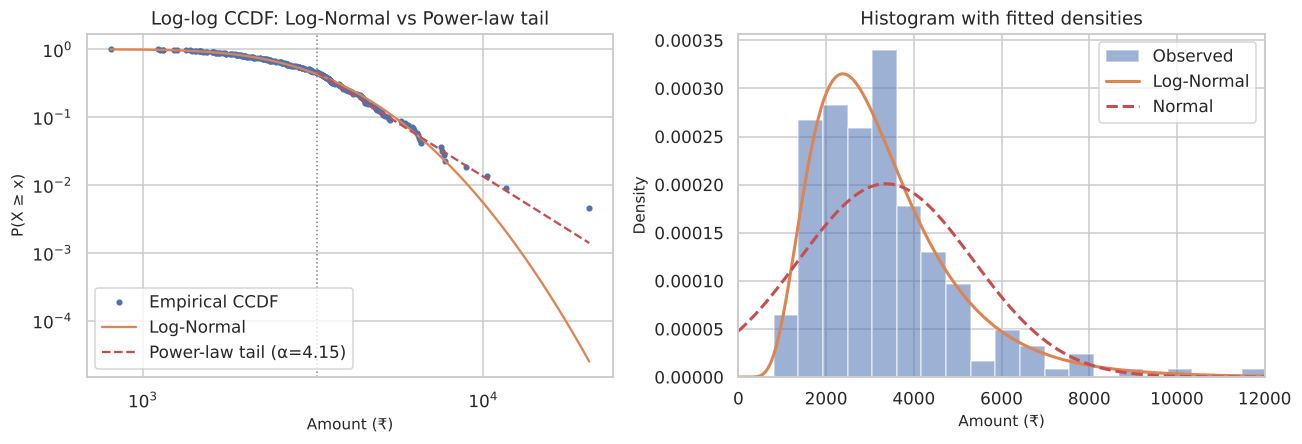

In [8]:
# ---- Power law only in the upper tail: Clauset-Shalizi-Newman approach ----
xs = np.sort(x)
def pl_alpha(t, xm):  return 1 + len(t) / np.sum(np.log(t / xm))
cands = []
for xm in xs[:-15]:                                   # keep at least 15 points in the tail
    t = xs[xs >= xm]; a = pl_alpha(t, xm); m = len(t)
    cdf = 1 - (t / xm) ** (1 - a)
    D = max(np.max(np.abs(cdf - np.arange(m) / m)), np.max(np.abs(cdf - np.arange(1, m + 1) / m)))
    cands.append((D, xm, a, m))
D_pl, xmin, alpha, m_tail = min(cands)
tail = xs[xs >= xmin]
print(f"Power-law tail: x_min=₹{xmin:,.2f}, alpha={alpha:.3f}, points in tail={m_tail} ({m_tail/n:.0%} of data), KS distance={D_pl:.4f}")
ks_tail = st.kstest(tail, lambda t: 1 - (t / xmin) ** (1 - alpha))
print(f"KS test power-law tail: stat={ks_tail.statistic:.4f}, p-value={ks_tail.pvalue:.4f} (approx.; xmin was optimised)")

# Compare with a Log-Normal truncated at x_min on the SAME tail data
def nll_trunc(par):
    m_, s_ = par
    if s_ <= 0: return 1e12
    d = st.lognorm(s_, 0, np.exp(m_)); sf = d.sf(xmin)
    return -(d.logpdf(tail).sum() - len(tail) * np.log(sf))
r = minimize(nll_trunc, [mu_log, sigma_log], method="Nelder-Mead")
ll_ln_tail = -r.fun
ll_pl_tail = len(tail) * np.log((alpha - 1) / xmin) - alpha * np.sum(np.log(tail / xmin))
print(f"Tail log-likelihood: power law = {ll_pl_tail:.2f} | truncated log-normal = {ll_ln_tail:.2f}  (both 2 parameters incl. x_min handled equally)")
print("Better tail model:", "Log-Normal" if ll_ln_tail > ll_pl_tail else "Power law")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
# log-log complementary CDF
ecdf_y = 1 - np.arange(n) / n
ax[0].loglog(xs, ecdf_y, ".", color=PALETTE["obs"], label="Empirical CCDF")
grid = np.logspace(np.log10(xs.min()), np.log10(xs.max()), 300)
ax[0].loglog(grid, st.lognorm.sf(grid, s_ln, 0, sc_ln), color=PALETTE["fit"], label="Log-Normal")
gt = grid[grid >= xmin]
ax[0].loglog(gt, (m_tail / n) * (gt / xmin) ** (1 - alpha), "--", color=PALETTE["bad"], label=f"Power-law tail (α={alpha:.2f})")
ax[0].axvline(xmin, color="grey", ls=":", lw=1)
ax[0].set(title="Log-log CCDF: Log-Normal vs Power-law tail", xlabel="Amount (₹)", ylabel="P(X ≥ x)"); ax[0].legend()
# histogram with fits
ax[1].hist(x, bins=35, density=True, alpha=.55, color=PALETTE["obs"], label="Observed")
g = np.linspace(0, 12000, 600)
ax[1].plot(g, st.lognorm.pdf(g, s_ln, 0, sc_ln), color=PALETTE["fit"], lw=2, label="Log-Normal")
ax[1].plot(g, st.norm.pdf(g, mu, sd), color=PALETTE["bad"], lw=2, ls="--", label="Normal")
ax[1].set(title="Histogram with fitted densities", xlabel="Amount (₹)", ylabel="Density", xlim=(0, 12000)); ax[1].legend()
plt.tight_layout(); SAVE("05_lognormal_powerlaw"); plt.show()

**Interpretation.** Taken over the whole range, a power law is a poor description (whole-sample Pareto is rejected). If we restrict to the **upper tail** (amounts ≳ ₹3,250, about 46 % of transactions), a power-law exponent of **α ≈ 4.1** fits acceptably, which indicates a *thin* power-law tail (finite mean and variance, no "whale" dominance). On those same tail points, however, a truncated Log-Normal reaches practically the same log-likelihood (−833.9 for both), so the data cannot separate the two in the tail. The log-log CCDF adds a nuance: the Log-Normal curve follows the bulk of the data very well, but it **under-states the few most extreme orders** (the ₹10k to ₹20k transactions sit above the Log-Normal curve and closer to the power-law line). Conclusion: the **Log-Normal is the preferred model overall**, while a power-law tail is a useful refinement if the business cares specifically about extreme high-value orders.

## 5. Q-Q plot: testing normality

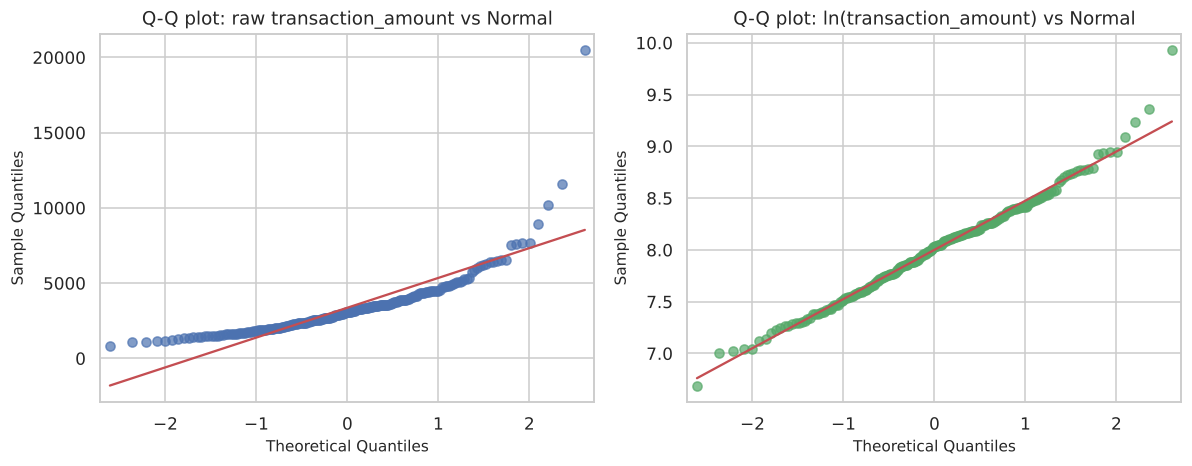

Shapiro-Wilk on raw amount : W=0.7361, p=1.91e-18  -> NOT normal | skew=3.730
Shapiro-Wilk on ln(amount) : W=0.9894, p=1.06e-01  -> consistent with normal | skew=0.311
D'Agostino K² on raw amount: NormaltestResult(statistic=np.float64(214.55522611197358), pvalue=np.float64(2.5699496691662404e-47))


In [9]:
logx = np.log(x)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
sm.qqplot(x, line="s", ax=ax[0], markerfacecolor=PALETTE["obs"], markeredgecolor=PALETTE["obs"], alpha=.7)
ax[0].set_title("Q-Q plot: raw transaction_amount vs Normal")
sm.qqplot(logx, line="s", ax=ax[1], markerfacecolor=PALETTE["alt"], markeredgecolor=PALETTE["alt"], alpha=.7)
ax[1].set_title("Q-Q plot: ln(transaction_amount) vs Normal")
plt.tight_layout(); SAVE("06_qq_plots"); plt.show()
for name, v in [("raw amount", x), ("ln(amount)", logx)]:
    w, p = st.shapiro(v)
    print(f"Shapiro-Wilk on {name:11s}: W={w:.4f}, p={p:.2e}  -> {'NOT normal' if p < .05 else 'consistent with normal'}"
          f" | skew={st.skew(v):.3f}")
print("D'Agostino K² on raw amount:", st.normaltest(x))

**Interpretation.** For raw amounts the points leave the reference line sharply at both ends, especially the upper tail (convex, "J-shaped" curve), which is the signature of right skewness and heavy upper tail. The Shapiro-Wilk test confirms this (W ≈ 0.74, p ≈ 2×10⁻¹⁸), so the data are **not normal**. After taking logarithms the points hug the line (Shapiro p ≈ 0.11, skewness falls from 3.73 to ≈ 0.31), so **ln(amount) is consistent with a Normal distribution**, which is precisely what it means for the amount to be Log-Normal.

## 6. Box-Cox transform (variance stabilisation)

Optimal Box-Cox lambda = -0.1808  (95% CI: -0.396 to 0.027)  -> close to 0 means ~ log transform
Skewness  before: 3.730  | after: -0.011
Kurtosis  before: 25.333 | after: 0.318
Shapiro p before: 1.91e-18 | after: 0.6419

Spread by region (raw):


,mean,std,CV (std/mean)
region,,,
East,3026.945,1327.820,0.439
North,3730.806,2956.619,0.792
South,3462.498,1866.419,0.539
West,3285.173,1653.617,0.503


Spread by region (Box-Cox):


,mean,std,CV (std/mean)
region,,,
East,4.203,0.115,0.027
North,4.241,0.109,0.026
South,4.231,0.113,0.027
West,4.222,0.108,0.026


Levene test (equal variance across regions): raw p=0.7290 | Box-Cox p=0.8793
Correlation(mean, std) across time blocks  raw: 0.98 | Box-Cox: 0.658


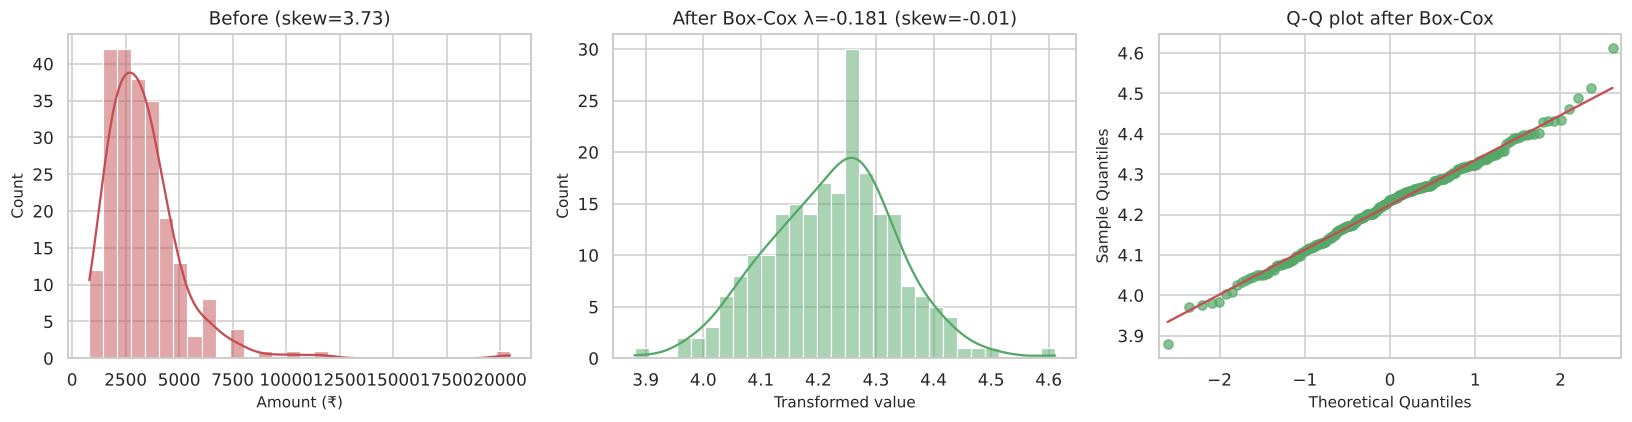

In [10]:
y, lam_bc = st.boxcox(x)
# 95 % confidence interval for lambda
_, _, ci = st.boxcox(x, alpha=0.05)
print(f"Optimal Box-Cox lambda = {lam_bc:.4f}  (95% CI: {ci[0]:.3f} to {ci[1]:.3f})  -> close to 0 means ~ log transform")
print(f"Skewness  before: {st.skew(x):.3f}  | after: {st.skew(y):.3f}")
print(f"Kurtosis  before: {st.kurtosis(x):.3f} | after: {st.kurtosis(y):.3f}")
print(f"Shapiro p before: {st.shapiro(x).pvalue:.2e} | after: {st.shapiro(y).pvalue:.4f}")

# Variance stabilisation: compare spread across regions and across date-groups (mean-variance relationship)
df["boxcox"] = y
def spread(frame, col, by):
    g = frame.groupby(by)[col]
    return pd.DataFrame({"mean": g.mean(), "std": g.std(), "CV (std/mean)": g.std() / g.mean()})
print("\nSpread by region (raw):");       display(spread(df, "transaction_amount", "region").round(3))
print("Spread by region (Box-Cox):");     display(spread(df, "boxcox", "region").round(3))
lev_raw = st.levene(*[g.transaction_amount.values for _, g in df.groupby("region")])
lev_bc  = st.levene(*[g.boxcox.values for _, g in df.groupby("region")])
print(f"Levene test (equal variance across regions): raw p={lev_raw.pvalue:.4f} | Box-Cox p={lev_bc.pvalue:.4f}")

# mean-vs-std relationship across 5 time blocks (variance should no longer grow with the mean)
df["block"] = pd.cut(df.transaction_date.dt.day, [0, 6, 12, 18, 24, 31], labels=False)
rb = spread(df, "transaction_amount", "block"); bb = spread(df, "boxcox", "block")
print("Correlation(mean, std) across time blocks  raw:", round(rb["mean"].corr(rb["std"]), 3), "| Box-Cox:", round(bb["mean"].corr(bb["std"]), 3))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(x, bins=30, kde=True, color=PALETTE["bad"], ax=ax[0]); ax[0].set(title=f"Before (skew={st.skew(x):.2f})", xlabel="Amount (₹)")
sns.histplot(y, bins=30, kde=True, color=PALETTE["alt"], ax=ax[1]); ax[1].set(title=f"After Box-Cox λ={lam_bc:.3f} (skew={st.skew(y):.2f})", xlabel="Transformed value")
sm.qqplot(y, line="s", ax=ax[2], markerfacecolor=PALETTE["alt"], markeredgecolor=PALETTE["alt"], alpha=.7); ax[2].set_title("Q-Q plot after Box-Cox")
plt.tight_layout(); SAVE("07_boxcox"); plt.show()

**Interpretation.** The maximum-likelihood Box-Cox exponent is **λ ≈ −0.18**, whose 95 % confidence interval includes **0**, so a plain **log transform is statistically justified**. After the transform the skewness drops from ≈ 3.73 to ≈ −0.01 and the Shapiro-Wilk test no longer rejects normality (p ≈ 0.64). **Variance stabilisation:** on the raw scale the standard deviation grows with the mean (correlation 0.98 across five time blocks, and regional standard deviations range from ₹1,328 to ₹2,957, a 2.2× gap), whereas after Box-Cox the correlation falls to 0.66 and regional standard deviations are almost identical (0.108 to 0.115). Levene's test is not significant on either scale (p = 0.73 raw, 0.88 transformed), so the regions never differed significantly in variance; the real gain is the removal of the mean-variance dependence and the skewness. The Q-Q plot now follows the straight line. The Box-Cox data can therefore safely be used for methods that assume normality and constant variance (t-tests, ANOVA, linear regression).

## 7. Z-scores & probability of a transaction exceeding ₹5,000

Mean = ₹3,365.19, Std = ₹1,985.71
Z-score summary:


,count,mean,std,min,25%,50%,75%,max
z_score,220.0,0.0,1.0,-1.29,-0.625,-0.145,0.295,8.61


Outliers with |z| > 3: 3


,customer_id,transaction_amount,region,transaction_status,z_score
209,CUST4116,20462.84,North,Fail,8.61
179,CUST1514,11615.37,South,Fail,4.15
113,CUST9797,10215.09,North,Success,3.45


Observations with |z| > 2: 8

Z-score of ₹5,000 = (5000 - 3365.19) / 1985.71 = 0.8233


,Method,P(amount > 5000),Expected out of 220
0,Empirical (count),0.1136,25.0
1,Normal (Z-score),0.2052,45.1
2,Log-Normal,0.1384,30.5
3,Box-Cox + Normal,0.1388,30.5


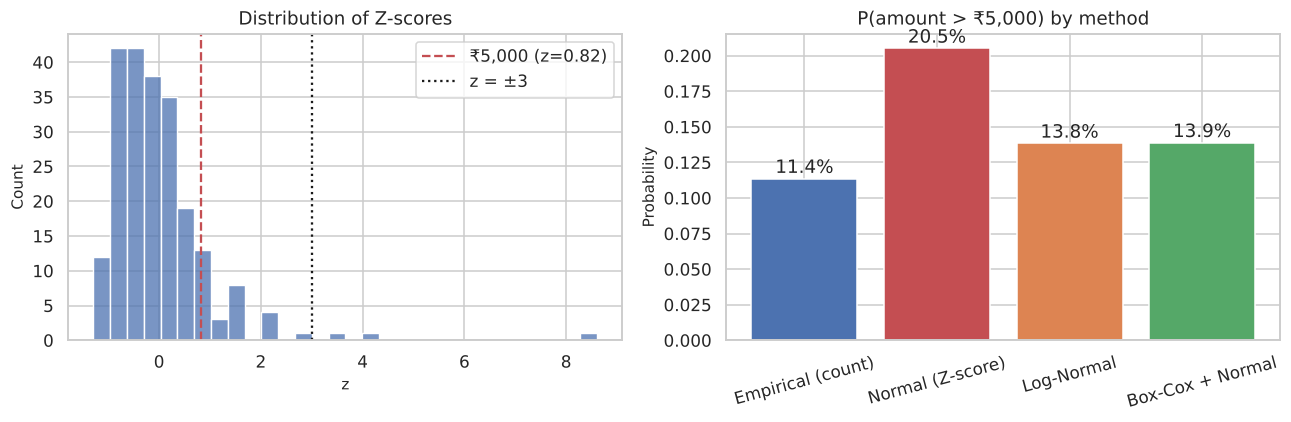

In [11]:
df["z_score"] = (df.transaction_amount - mu) / sd
print(f"Mean = ₹{mu:,.2f}, Std = ₹{sd:,.2f}")
print("Z-score summary:"); display(df["z_score"].describe().round(3).to_frame().T)
out = df.loc[df.z_score.abs() > 3, ["customer_id", "transaction_amount", "region", "transaction_status", "z_score"]].sort_values("z_score", ascending=False)
print(f"Outliers with |z| > 3: {len(out)}"); display(out.round(2))
print(f"Observations with |z| > 2: {(df.z_score.abs() > 2).sum()}")

thr = 5000
z5 = (thr - mu) / sd
p_emp  = (x > thr).mean()
p_norm = 1 - st.norm.cdf(z5)                                  # classic Z-score approach
p_ln   = st.lognorm.sf(thr, s_ln, 0, sc_ln)                   # Log-Normal model
z_bc   = (st.boxcox(np.array([thr]), lmbda=lam_bc)[0] - y.mean()) / y.std(ddof=1)
p_bc   = 1 - st.norm.cdf(z_bc)                                # Normal model on Box-Cox scale
res = pd.DataFrame({"Method": ["Empirical (count)", "Normal (Z-score)", "Log-Normal", "Box-Cox + Normal"],
                    "P(amount > 5000)": [p_emp, p_norm, p_ln, p_bc]})
res["Expected out of 220"] = (res["P(amount > 5000)"] * n).round(1)
print(f"\nZ-score of ₹5,000 = ({thr} - {mu:.2f}) / {sd:.2f} = {z5:.4f}")
display(res.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df.z_score, bins=30, color=PALETTE["obs"], ax=ax[0]); ax[0].axvline(z5, color=PALETTE["bad"], ls="--", label=f"₹5,000 (z={z5:.2f})")
ax[0].axvline(3, color="k", ls=":", label="z = ±3"); ax[0].set(title="Distribution of Z-scores", xlabel="z"); ax[0].legend()
ax[1].bar(res["Method"], res["P(amount > 5000)"], color=[PALETTE["obs"], PALETTE["bad"], PALETTE["fit"], PALETTE["alt"]])
for i, v in enumerate(res["P(amount > 5000)"]): ax[1].text(i, v + .004, f"{v:.1%}", ha="center")
ax[1].set(title="P(amount > ₹5,000) by method", ylabel="Probability"); ax[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); SAVE("08_zscore_probability"); plt.show()

**Interpretation.** ₹5,000 sits about **0.82 standard deviations** above the mean. The textbook Normal/Z-score method gives **P ≈ 20.5 %**, which clearly *over-states* the true frequency, because the Normal model wrongly assumes a symmetric distribution. The empirical share is **11.4 %** (25 of 220 transactions). The Log-Normal (13.8 %) and Box-Cox-Normal (13.9 %) estimates are far closer to reality. Three transactions have |z| > 3 and the largest (₹20,463) has z ≈ 8.6, a genuine extreme outlier that should be reviewed for fraud or bulk/B2B orders. **Lesson: Z-score probabilities are only reliable once the data is (approximately) normal, so use the Box-Cox/log scale for skewed money data.**

## 8. PDF & CDF of transaction amounts

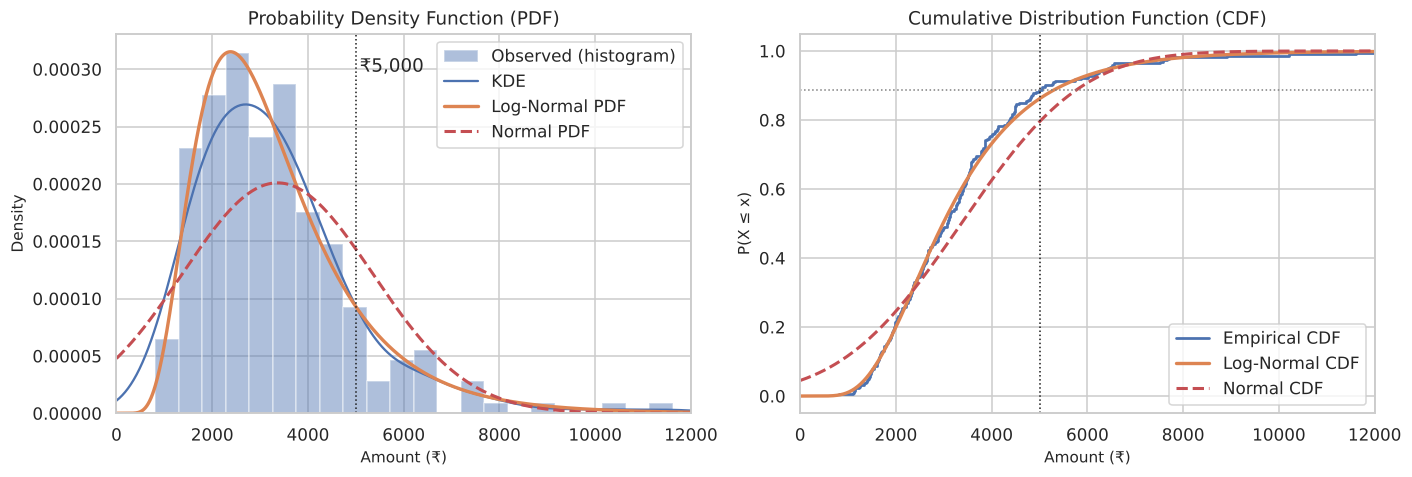

,Percentile,Empirical (₹),Log-Normal (₹),Normal (₹)
0,10,1618.0,1623.0,820.0
1,25,2124.0,2166.0,2026.0
2,50,3078.0,2983.0,3365.0
3,75,3951.0,4110.0,4705.0
4,90,5137.0,5483.0,5910.0
5,95,6434.0,6515.0,6631.0
6,99,9968.0,9005.0,7985.0


In [12]:
g = np.linspace(0, 12000, 800)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
# PDF
ax[0].hist(x, bins=40, density=True, alpha=.45, color=PALETTE["obs"], label="Observed (histogram)")
sns.kdeplot(x, ax=ax[0], color=PALETTE["obs"], lw=1.5, label="KDE", clip=(0, 12000))
ax[0].plot(g, st.lognorm.pdf(g, s_ln, 0, sc_ln), color=PALETTE["fit"], lw=2.2, label="Log-Normal PDF")
ax[0].plot(g, st.norm.pdf(g, mu, sd), color=PALETTE["bad"], lw=2, ls="--", label="Normal PDF")
ax[0].axvline(thr, color="k", ls=":", lw=1); ax[0].text(thr + 80, ax[0].get_ylim()[1] * .9, "₹5,000")
ax[0].set(title="Probability Density Function (PDF)", xlabel="Amount (₹)", ylabel="Density", xlim=(0, 12000)); ax[0].legend()
# CDF
ax[1].step(xs, np.arange(1, n + 1) / n, where="post", color=PALETTE["obs"], lw=1.8, label="Empirical CDF")
ax[1].plot(g, st.lognorm.cdf(g, s_ln, 0, sc_ln), color=PALETTE["fit"], lw=2.2, label="Log-Normal CDF")
ax[1].plot(g, st.norm.cdf(g, mu, sd), color=PALETTE["bad"], lw=2, ls="--", label="Normal CDF")
ax[1].axvline(thr, color="k", ls=":", lw=1); ax[1].axhline(1 - p_emp, color="grey", ls=":", lw=1)
ax[1].set(title="Cumulative Distribution Function (CDF)", xlabel="Amount (₹)", ylabel="P(X ≤ x)", xlim=(0, 12000)); ax[1].legend(loc="lower right")
plt.tight_layout(); SAVE("09_pdf_cdf"); plt.show()

q = pd.DataFrame({"Percentile": [10, 25, 50, 75, 90, 95, 99]})
q["Empirical (₹)"] = np.percentile(x, q.Percentile)
q["Log-Normal (₹)"] = st.lognorm.ppf(q.Percentile / 100, s_ln, 0, sc_ln)
q["Normal (₹)"] = st.norm.ppf(q.Percentile / 100, mu, sd)
display(q.round(0).astype({"Percentile": int}))

**Interpretation.** The PDF shows a single-peaked, right-skewed shape with the mode around ₹2,400; the Log-Normal curve follows the histogram closely whereas the Normal curve peaks too low, is centred to the right of the true mode, and even assigns probability to negative amounts. In the CDF, the empirical and Log-Normal curves almost coincide (max gap ≈ 0.038), while the Normal CDF deviates visibly. About **50 %** of transactions are below ₹3,078 (median) and about **88.6 %** are below ₹5,000. The percentile table shows the Normal model badly mis-states both ends: it puts the 10th percentile at ₹820 (actual ₹1,618) and the 99th at ₹7,985 (actual ₹9,968), whereas the Log-Normal is within a few percent for most percentiles.

## 9. Conclusion & decision-making insights

In [13]:
summary = pd.DataFrame({
    "Variable": ["Transaction status", "Weekly transaction_count", "Transactions per day", "transaction_amount", "transaction_amount", "transaction_amount (tail)"],
    "Model": ["Bernoulli", "Binomial", "Poisson", "Log-Normal", "Normal", "Power law"],
    "Key parameters": [f"p = {p_succ:.3f}", f"n = {n_trials}, p = {p_bin:.3f}", f"λ = {lam:.2f}",
                       f"μ = {mu_log:.2f}, σ = {sigma_log:.2f}", f"μ = {mu:,.0f}, σ = {sd:,.0f}", f"α = {alpha:.2f}, x_min = {xmin:,.0f}"],
    "Verdict": ["Appropriate (binary outcome)", "Rejected (χ² p<0.001), over-dispersed", "Acceptable (slightly under-dispersed)",
                "BEST FIT (KS p=%.2f, lowest AIC)" % cmp_df.loc["Log-Normal", "KS p-value"],
                "Rejected (KS p=%.4f)" % cmp_df.loc["Normal", "KS p-value"], "Tail approximation only"]})
display(summary)

,Variable,Model,Key parameters,Verdict
0,Transaction status,Bernoulli,p = 0.445,Appropriate (binary outcome)
1,Weekly transaction_count,Binomial,"n = 9, p = 0.317","Rejected (χ² p<0.001), over-dispersed"
2,Transactions per day,Poisson,λ = 7.10,Acceptable (slightly under-dispersed)
3,transaction_amount,Log-Normal,"μ = 8.00, σ = 0.47","BEST FIT (KS p=0.90, lowest AIC)"
4,transaction_amount,Normal,"μ = 3,365, σ = 1,986",Rejected (KS p=0.0003)
5,transaction_amount (tail),Power law,"α = 4.15, x_min = 3,248",Tail approximation only


### Final conclusion

**Which distribution best fits the data? → The Log-Normal distribution** (μ ≈ 8.00, σ ≈ 0.47) for `transaction_amount`.

| Evidence | Result |
|---|---|
| Information criteria | Lowest AIC/BIC of Normal, Log-Normal, Pareto |
| Kolmogorov-Smirnov | Log-Normal p ≈ 0.90 (not rejected); Normal p ≈ 0.0003 and Pareto p ≈ 0 (rejected) |
| Q-Q plot / Shapiro-Wilk | Raw: not normal (p ≈ 10⁻¹⁸); ln(x): normal (p ≈ 0.11) |
| Box-Cox λ | ≈ −0.18, CI contains 0, i.e. log transform |
| Extreme tail | Log-Normal slightly under-states the largest orders (99th pct ₹9,005 vs ₹9,968 actual); power-law tail (α ≈ 4.1) is a reasonable refinement above ≈ ₹3,250 |
| Tail probability P(>₹5,000) | Log-Normal 13.8 % vs empirical 11.4 % (Normal says 20.5 %) |

### Business insights & recommendations
1. **Use the Log-Normal (or log/Box-Cox-transformed data) for all amount analytics.** Report the *median* (₹3,078) and percentiles instead of the mean, which is inflated by a few very large orders.
2. **Do not use plain Z-scores / Normal assumptions on raw amounts.** They overstate the chance of high-value orders (20.5 % vs actual 11.4 %) and could mis-size inventory, credit limits and revenue forecasts.
3. **Review extreme transactions.** Three orders have |z| > 3 (the largest is ₹20,463, z ≈ 8.6). Flag these for fraud checks or route them to a B2B/high-value workflow.
4. **Failed-payment rate is a priority.** Only 44.5 % of transactions succeed (55.5 % fail). Improving payment gateway reliability is the single biggest revenue lever in this data.
5. **Capacity planning.** Daily volume is well-modelled by Poisson (λ ≈ 7.1 per day); the probability of a ≥ 10-transaction day is ≈ 18 % (22.6 % observed), which is useful for support-staff and server sizing.
6. **Customer activity is high but uneven.** About 93 % of customer-weeks have at least one transaction, but weekly counts are more dispersed than a Binomial predicts, and the Binomial is rejected, so segment customers (light vs heavy buyers) rather than assuming homogeneity.

### Limitations
The dataset has only 220 records over 31 days (January 2023), so tail estimates (power law, 99th percentile) are uncertain. Results should be re-validated on a larger sample.